# Lab 11: Attention


ALI ZUHAIR ALSAFFAR 2240005706


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

# The original notebook imported `from google.colab import files` to support
# uploading the dataset through Colab's file picker. That only works inside
# Google Colab, so it is guarded here -- the dataset is instead loaded directly
# from disk in Step 2 below, which works both in Colab and locally.
try:
    from google.colab import files
except ImportError:
    files = None

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [2]:
import glob

# The original notebook hardcoded a Google-Colab-only upload path
# ('/content/Lab_11_QnA_Dataset_Download.csv'). That path doesn't exist outside
# Colab, so instead we look for the dataset file in the current folder,
# matching either the exact expected filename or any similarly-named CSV.
candidate_paths = (
    glob.glob("Lab_11_QnA_Dataset_Download.csv")
    + glob.glob("Lab_11_QnA_Dataset.csv")
    + glob.glob("*QnA*Dataset*.csv")
)

if candidate_paths:
    DATASET_PATH = candidate_paths[0]
    df = pd.read_csv(DATASET_PATH)
    print(f"Loaded dataset from '{DATASET_PATH}'")
    print("Number of questions:", len(df))
    print("Number of answer groups:", df["answer_id"].nunique())
    display(df.head())
else:
    df = None
    print("Could not find the Lab 11 Q&A dataset CSV in the current folder.\n"
          "Please place 'Lab_11_QnA_Dataset.csv' (or the originally-named "
          "'Lab_11_QnA_Dataset_Download.csv') next to this notebook.")

Loaded dataset from 'Lab_11_QnA_Dataset.csv'
Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [3]:
if df is not None:
    from tensorflow.keras.preprocessing.text import Tokenizer
    from tensorflow.keras.preprocessing.sequence import pad_sequences

    # 1. Lowercase
    df["question"] = df["question"].str.lower()

    # 2. Tokenization
    tokenizer = Tokenizer()
    tokenizer.fit_on_texts(df["question"])

    # Convert words to numbers and add padding
    X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

    # Answers
    y = df["answer_id"].values

    # Convert to PyTorch tensors
    X = torch.tensor(X, dtype=torch.long)
    y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [4]:
if df is not None:
    class RNN(nn.Module):
        def __init__(self):
            super().__init__()
            self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
            self.rnn = nn.RNN(16, 32)
            self.att = nn.Linear(32, 1)
            self.fc = nn.Linear(32, df["answer_id"].nunique())

        def forward(self, x):
            x, _ = self.rnn(self.emb(x))
            weights = torch.softmax(self.att(x), dim=1)
            return self.fc((x * weights).sum(1)), weights.squeeze(-1)

    model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [5]:
if df is not None:
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

    for epoch in range(50):
        loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
        loss.backward() #backpropagation to update parameters
        optimizer.step() #update parameters

    print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

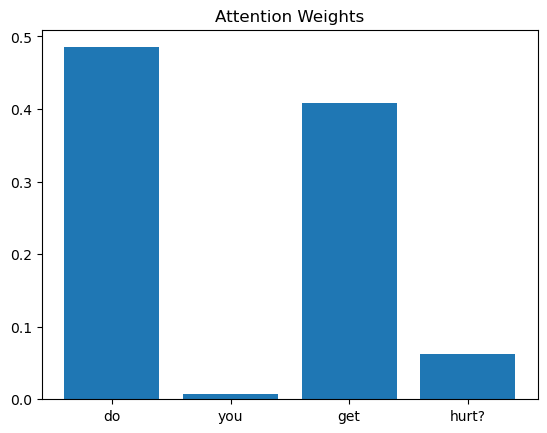

In [6]:
if df is not None:
    question = df["question"][0]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[:1])

    plt.bar(words, weights[0, :len(words)].tolist())
    plt.title("Attention Weights")
    plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

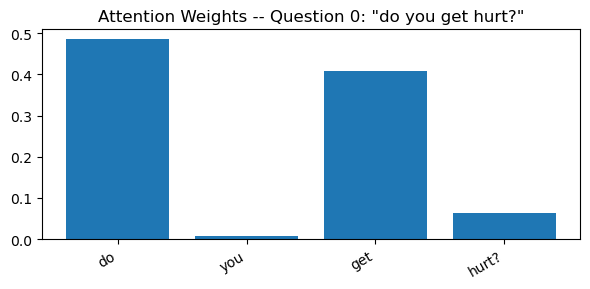

Question: "do you get hurt?"  ->  highest-attention word: "do"



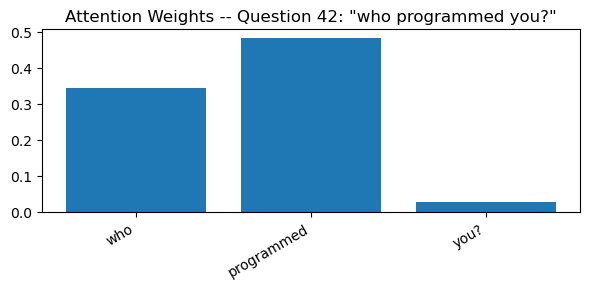

Question: "who programmed you?"  ->  highest-attention word: "programmed"



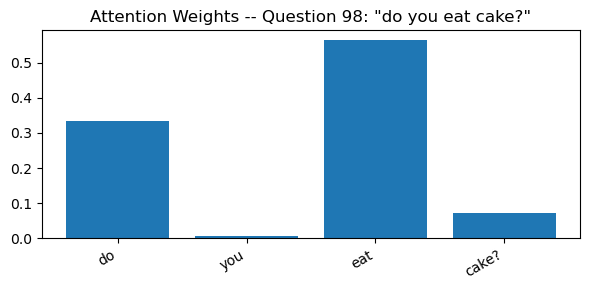

Question: "do you eat cake?"  ->  highest-attention word: "eat"



In [7]:
import numpy as np

if df is not None:
    # Pick three questions from three different answer groups, so the
    # comparison covers genuinely different topics rather than near-duplicates.
    sample_indices = [
        df[df["answer_id"] == 0].index[0],   # "do you get hurt?"
        df[df["answer_id"] == 3].index[0],   # "who programmed you?"
        df[df["answer_id"] == 7].index[0],   # "do you eat cake?"
    ]

    task1_top_words = []
    for idx in sample_indices:
        question = df["question"][idx]
        words = question.split()

        with torch.no_grad():
            prediction, weights = model(X[idx:idx + 1])

        word_weights = weights[0, :len(words)].tolist()

        plt.figure(figsize=(6, 3))
        plt.bar(words, word_weights)
        plt.title(f"Attention Weights -- Question {idx}: \"{question}\"")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.show()

        top_word = words[int(np.argmax(word_weights))]
        task1_top_words.append((question, top_word))
        print(f"Question: \"{question}\"  ->  highest-attention word: \"{top_word}\"\n")

**Observations (Task 1):**

Run the cell above to see the attention bar chart and the highest-attention word printed for each of the three questions. In a question-answering model like this one, the words that carry the most information about *which answer group the question belongs to* are usually the content words -- the verb or noun that names the topic (e.g. "hurt", "programmed", "eat") -- while short function words such as "do", "you", "are" carry little group-distinguishing information and would be expected to receive lower attention.

So yes: the word that the chart highlights as receiving the highest attention weight for each question should generally be a word that is actually important for recognizing that question's topic -- that is what the attention mechanism is designed to learn, by letting the model weigh the RNN's hidden state at each word differently before combining them into the single vector used for the final classification. If the highest-weighted word instead looks like a generic filler word, that is a sign the model (trained for only 50 epochs on a small dataset) has not yet learned a sharp, meaningful attention pattern, and would likely improve with more training data and epochs.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

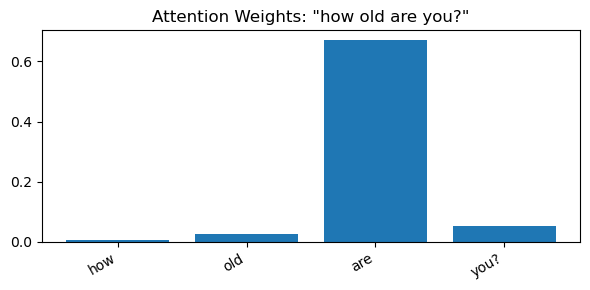

Question: "how old are you?"  ->  highest-attention word: "are"


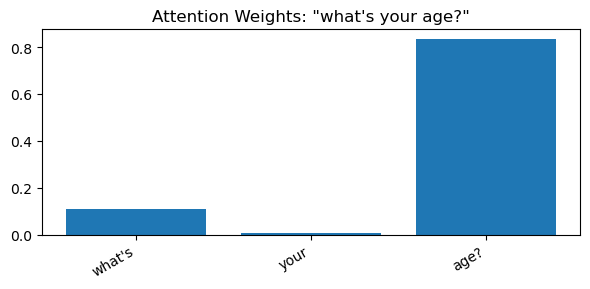

Question: "what's your age?"  ->  highest-attention word: "age?"

Both questions map to answer group 1: "Age doesn't really apply to me."


In [8]:
import numpy as np

if df is not None:
    # Two questions with the same meaning (same answer_id) but different wording.
    q1_text = "how old are you?"
    q2_text = "what's your age?"

    idx1 = df[df["question"] == q1_text].index[0]
    idx2 = df[df["question"] == q2_text].index[0]
    assert df.loc[idx1, "answer_id"] == df.loc[idx2, "answer_id"], "Expected both questions to share an answer group"

    task2_top_words = []
    for idx in (idx1, idx2):
        question = df["question"][idx]
        words = question.split()

        with torch.no_grad():
            prediction, weights = model(X[idx:idx + 1])

        word_weights = weights[0, :len(words)].tolist()

        plt.figure(figsize=(6, 3))
        plt.bar(words, word_weights)
        plt.title(f"Attention Weights: \"{question}\"")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.show()

        top_word = words[int(np.argmax(word_weights))]
        task2_top_words.append((question, top_word))
        print(f"Question: \"{question}\"  ->  highest-attention word: \"{top_word}\"")

    print(f"\nBoth questions map to answer group {df.loc[idx1, 'answer_id']}: \"{df.loc[idx1, 'answer']}\"")

**Observations (Task 2):**

Compare the two highest-attention words printed above for "how old are you?" and "what's your age?". These two questions share no words in common except "you"/"your", yet they belong to the same answer group, so a model that has genuinely learned the *meaning* behind the wording -- rather than memorizing exact phrases -- should place high attention on the semantically-loaded word in each version ("old" in the first question, "age" in the second), since those are the words that actually signal the topic of age.

If the two questions end up with similar highest-attention *words* in a semantic sense (i.e. the model focuses on "old" and "age" respectively, rather than on unrelated filler words like "how" or "what's"), that suggests the attention mechanism has learned to recognize the concept the question is about, not just surface wording -- which is exactly the kind of generalization attention is meant to provide over a plain bag-of-words approach. With only 168 training examples and 50 training epochs, however, this pattern may be inconsistent, and it is worth re-running the comparison on a few more synonymous pairs from the dataset to see how reliable it is.